# Road Accident Severity
**โจทย์:** ถ้าเกิดอุบัติเหตุบนถนนเส้นนี้ ที่หลัก กม. นี้ ในสถานการณ์แบบนี้ มีโอกาสกี่ % ที่จะรุนแรง

- **กรอกอะไร:** ถนน + หลัก กม., ลักษณะทาง, รถและคนที่เกี่ยวข้อง, ชั่วโมง, ฝนตกหรือไม่
- **ได้อะไร:** % โอกาสที่อุบัติเหตุจะรุนแรง (`severe` = มีผู้เสียชีวิตหรือบาดเจ็บสาหัสอย่างน้อย 1 คน)
- **เอาไปทำอะไร:** เทียบว่าปัจจัยใดทำให้ % รุนแรงเพิ่มขึ้นมากที่สุด

**ลำดับในไฟล์นี้:** 1) Import Dataset → 2) EDA → 3) Model Planning → 4) Build a model → 5) Evaluation → 6) Comparing factors → 7) Save model → 8) Conclusion

**รายชื่อสมาชิก**
  

1.   สิริภัท ธนสุขโสภณ 6809540179
2.   ภณวรรชน์ โขงเขตต์ 6809617282
3.   รมณ ประภาพรสุข 6809617332   
4.   วิรมณ มาเกิด 6809617407   
5.   อานัส บินเสะ 6809617522   
6.   ณพวุฒิ วิทยากุล 6809681429   
7.   ปาณิศรา แวงดิศร 6809681452   
8.   ศรัณย์วิชญ์ โพธิ์ชัย 6809681478   
9.   อานนท์ พูนสิน 6809681494   


**หัวข้อเรื่อง : ปัจจัยที่ส่งผลต่อความอันตรายของอุบัติเหตุทางท้องถนน**

วัตถุประสงค์ (Objectives)

แหล่งที่มาของข้อมูล จากเว็บไซต์ ระบบบัญชีข้อมูลด้านคมนาคม MOT Data Catalog หัวข้อ อุบัติเหตุบนโครงข่ายถนนของกระทรวงคมนาคม https://datagov.mot.go.th/dataset/roadaccident

## 1. Import Dataset (local version)
ข้อมูลอุบัติเหตุทางถนนปี 2020–2026 จำนวน 7 ไฟล์ อ่านจากโฟลเดอร์ `data/datagov/` (ถ้ารันบน Colab ให้แก้ path ใน cell ที่ค้นหาไฟล์)

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import glob
import os

In [2]:
# Import libraries สำหรับวาดกราฟและสร้างโมเดล
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

plt.rcParams["figure.figsize"] = (8, 4)
# ฟอนต์สำรองสำหรับตัวอักษรไทยในกราฟ
plt.rcParams["font.family"] = ["DejaVu Sans", "Tahoma"]

In [3]:
files = sorted(
    glob.glob(
        "data/datagov/accident202*.csv",
        recursive=True
    )
)

print("พบไฟล์:", len(files))

for file in files:
    print(os.path.basename(file))

พบไฟล์: 7
accident2020.csv
accident2021.csv
accident2022.csv
accident2023.csv
accident2024.csv
accident2025.csv
accident2026.csv


### เปลี่ยนชื่อคอลัมน์เป็นภาษาอังกฤษ และรวมไฟล์ 7 ปี

In [4]:
column_map = {
    "ปีที่เกิดเหตุ": "accident_year",
    "วันที่เกิดเหตุ": "accident_date",
    "เวลา": "accident_time",
    "วันที่รายงาน": "report_date",
    "เวลาที่รายงาน": "report_time",

    "ACC_CODE": "accident_code",
    "หน่วยงาน": "agency",
    "สายทางหน่วยงาน": "road_agency",
    "รหัสสายทาง": "road_code",
    "สายทาง": "road_name",

    "KM": "kilometer",
    "ก.ม.": "kilometer",

    "จังหวัด": "province",
    "รถคันที่1": "first_vehicle",

    "บริเวณที่เกิดเหตุ": "accident_location",
    "บริเวณที่เกิดเหตุ/ลักษณะทาง": "accident_location",
    "บริเวณที่เกิดเหตุอื่น": "accident_location_other",

    "มูลเหตุสันนิษฐาน": "suspected_cause",

    "ลักษณะการเกิดเหตุ": "accident_type",
    "ลักษณะการเกิดอุบัติเหตุ": "accident_type",

    "สภาพอากาศ": "weather",
    "LATITUDE": "latitude",
    "LONGITUDE": "longitude",

    "รถที่เกิดเหตุ": "vehicle_count",
    "จำนวนรถที่เกิดเหตุ(รวมคันที่1)": "vehicle_count",

    "รถและคนที่เกิดเหตุ": "involved_count",
    "จำนวนที่เกิดเหตุทั้งหมด(รวมคนเดินเท้า)": "involved_count",

    "รถจักรยานยนต์": "motorcycle_count",
    "รถสามล้อเครื่อง": "motor_tricycle_count",

    "รถยนต์นั่งส่วนบุคคล": "passenger_car_count",
    "รถยนต์นั่งส่วนบุคคล/รถยนต์นั่งสาธารณะ":
        "passenger_car_count",

    "รถตู้": "van_count",
    "รถปิคอัพโดยสาร": "passenger_pickup_count",

    "รถโดยสารมากกว่า4ล้อ":
        "bus_over_4_wheels_count",

    "รถปิคอัพบรรทุก4ล้อ":
        "cargo_pickup_4_wheels_count",

    "รถบรรทุก6ล้อ":
        "truck_6_wheels_count",

    "รถบรรทุกไม่เกิน10ล้อ":
        "truck_7_to_10_wheels_count",

    "รถบรรทุกมากกว่า6ล้อไม่เกิน10ล้อ":
        "truck_7_to_10_wheels_count",

    "รถบรรทุกมากกว่า10ล้อ":
        "truck_over_10_wheels_count",

    "รถบรรทุกมากกว่า10ล้อ(รถพ่วง)":
        "truck_over_10_wheels_count",

    "รถอีแต๋น": "farm_truck_count",

    "รถอื่นๆ": "other_vehicle_count",
    "อื่นๆ": "other_vehicle_count",

    "คนเดินเท้า": "pedestrian_count",

    "ผู้เสียชีวิต": "fatality_count",
    "จำนวนผู้เสียชีวิต": "fatality_count",

    "ผู้บาดเจ็บสาหัส": "serious_injury_count",
    "จำนวนผู้บาดเจ็บสาหัส": "serious_injury_count",

    "ผู้บาดเจ็บเล็กน้อย": "minor_injury_count",
    "จำนวนผู้บาดเจ็บเล็กน้อย": "minor_injury_count",

    "รวมจำนวนผู้บาดเจ็บ": "total_injury_count"
}

In [5]:
# Convert Excel serial date to date text
# ตัวอย่าง 45292 -> 1/1/2024

def excel_date_to_text(series):
    numeric_values = pd.to_numeric(
        series,
        errors="coerce"
    )

    converted_dates = pd.to_datetime(
        numeric_values,
        unit="D",
        origin="1899-12-30",
        errors="coerce"
    )

    return converted_dates.map(
        lambda value:
        f"{value.day}/{value.month}/{value.year}"
        if pd.notna(value)
        else pd.NA
    )


# Convert Excel time fraction to HH:MM
# ตัวอย่าง 0.008333333 -> 00:12

def excel_time_to_text(series):
    numeric_values = pd.to_numeric(
        series,
        errors="coerce"
    )

    total_minutes = np.rint(
        numeric_values * 24 * 60
    )

    def format_time(value):
        if pd.isna(value):
            return pd.NA

        value = int(value) % 1440

        hour = value // 60
        minute = value % 60

        return f"{hour:02d}:{minute:02d}"

    return total_minutes.map(format_time)

In [6]:
# Read and standardize each yearly CSV file

frames = []

for file in files:
    temp_df = pd.read_csv(file)

    # Remove spaces from column names
    temp_df.columns = temp_df.columns.str.strip()

    # Get year from filename
    # เช่น accident2024.csv -> 2024
    file_year = int(
        os.path.basename(file)
        .replace("accident", "")
        .replace(".csv", "")
    )

    # Year 2024:
    # Convert accident/report dates and times
    if file_year == 2024:
        temp_df["วันที่เกิดเหตุ"] = (
            excel_date_to_text(
                temp_df["วันที่เกิดเหตุ"]
            )
        )

        temp_df["วันที่รายงาน"] = (
            excel_date_to_text(
                temp_df["วันที่รายงาน"]
            )
        )

        temp_df["เวลา"] = (
            excel_time_to_text(
                temp_df["เวลา"]
            )
        )

        temp_df["เวลาที่รายงาน"] = (
            excel_time_to_text(
                temp_df["เวลาที่รายงาน"]
            )
        )

    # Year 2025:
    # Convert accident/report dates only
    elif file_year == 2025:
        temp_df["วันที่เกิดเหตุ"] = (
            excel_date_to_text(
                temp_df["วันที่เกิดเหตุ"]
            )
        )

        temp_df["วันที่รายงาน"] = (
            excel_date_to_text(
                temp_df["วันที่รายงาน"]
            )
        )

    # Rename columns to English
    temp_df = temp_df.rename(
        columns=column_map
    )

    frames.append(temp_df)


# Combine all years
df = pd.concat(
    frames,
    ignore_index=True
)

print("ขนาดข้อมูลรวม:", df.shape)
print("จำนวนคอลัมน์:", len(df.columns))

ขนาดข้อมูลรวม: (151823, 39)
จำนวนคอลัมน์: 39


### ปรับรูปแบบวันที่และเวลา
ไฟล์แต่ละปีเขียนวันที่ไม่เหมือนกัน: ปี 2020, 2021, 2023 เขียนแบบ เดือน/วัน/ปี ส่วนปีอื่นอ่านแบบ วัน/เดือน/ปี ได้ถูก

In [7]:
# Convert date columns of every year to datetime

date_columns = [
    "accident_date",
    "report_date"
]

# แก้ไข: ไฟล์บางปีเขียนวันที่แบบ เดือน/วัน/ปี จึงต้องอ่านแบบเดือนมาก่อน
# ส่วนปีที่เหลืออ่านแบบวันมาก่อนเหมือนเดิม
month_first_years = {
    "accident_date": [2020, 2021, 2023],
    "report_date": [2020, 2021, 2022, 2023]
}

for column in date_columns:
    month_first = df["accident_year"].isin(
        month_first_years[column]
    )

    month_first_dates = pd.to_datetime(
        df.loc[month_first, column],
        format="%m/%d/%Y",
        errors="coerce"
    )

    day_first_dates = pd.to_datetime(
        df.loc[~month_first, column],
        format="mixed",
        dayfirst=True,
        errors="coerce"
    )

    df[column] = pd.concat([
        month_first_dates,
        day_first_dates
    ])

In [8]:
# ตรวจว่าอ่านวันที่ถูก: ในไฟล์ เหตุเรียงตามเวลา ดังนั้นวันเกิดเหตุของแต่ละปีต้องไม่ย้อนหลัง
for year in sorted(df["accident_year"].unique()):
    dates = df.loc[df["accident_year"] == year, "accident_date"]
    backward = (dates.diff().dt.days < 0).sum()
    print(year, "| จำนวนจุดที่วันที่ย้อนหลัง:", backward)

2020 | จำนวนจุดที่วันที่ย้อนหลัง: 0
2021 | จำนวนจุดที่วันที่ย้อนหลัง: 0
2022 | จำนวนจุดที่วันที่ย้อนหลัง: 0
2023 | จำนวนจุดที่วันที่ย้อนหลัง: 0
2024 | จำนวนจุดที่วันที่ย้อนหลัง: 0
2025 | จำนวนจุดที่วันที่ย้อนหลัง: 0
2026 | จำนวนจุดที่วันที่ย้อนหลัง: 0


In [9]:
# Standardize time columns to HH:MM

def normalize_time(series):
    time_parts = (
        series
        .astype("string")
        .str.extract(
            r"^\s*(\d{1,2}):(\d{1,2})"
            r"(?::\d{1,2})?\s*$"
        )
    )

    hours = pd.to_numeric(
        time_parts[0],
        errors="coerce"
    )

    minutes = pd.to_numeric(
        time_parts[1],
        errors="coerce"
    )

    valid_time = (
        hours.between(0, 23)
        & minutes.between(0, 59)
    )

    result = pd.Series(
        pd.NA,
        index=series.index,
        dtype="string"
    )

    result.loc[valid_time] = (
        hours.loc[valid_time]
        .astype(int)
        .astype(str)
        .str.zfill(2)
        + ":"
        + minutes.loc[valid_time]
        .astype(int)
        .astype(str)
        .str.zfill(2)
    )

    return result


time_columns = [
    "accident_time",
    "report_time"
]

for column in time_columns:
    df[column] = normalize_time(
        df[column]
    )

In [10]:
display(
    df.loc[
        df["accident_year"].isin(
            [2024, 2025]
        ),
        [
            "accident_year",
            "accident_date",
            "accident_time",
            "report_date",
            "report_time"
        ]
    ].head(20)
)

,accident_year,accident_date,accident_time,report_date,report_time
85708,2024,2024-01-01,00:12,2024-06-18,14:23
85709,2024,2024-01-01,00:30,2024-01-01,12:13
85710,2024,2024-01-01,00:30,2024-01-02,04:18
85711,2024,2024-01-01,00:30,2024-01-01,11:40
85712,2024,2024-01-01,00:30,2024-01-02,05:10
85713,2024,2024-01-01,00:30,2024-01-02,12:29
85714,2024,2024-01-01,00:30,2024-01-02,12:28
85715,2024,2024-01-01,00:30,2024-03-05,13:28
85716,2024,2024-01-01,00:30,2024-03-27,11:29
85717,2024,2024-01-01,00:30,2024-11-21,11:43


In [11]:
print(
    df[
        [
            "accident_date",
            "accident_time",
            "report_date",
            "report_time"
        ]
    ].dtypes
)

accident_date    datetime64[us]
accident_time            string
report_date      datetime64[us]
report_time              string
dtype: object


## 2. EDA: see data

### 2.1 Stats

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 151823 entries, 0 to 151822
Data columns (total 39 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   accident_year                151823 non-null  int64         
 1   accident_date                151822 non-null  datetime64[us]
 2   accident_time                151822 non-null  string        
 3   report_date                  151740 non-null  datetime64[us]
 4   report_time                  151735 non-null  string        
 5   accident_code                133375 non-null  float64       
 6   agency                       151823 non-null  str           
 7   road_agency                  151823 non-null  str           
 8   road_code                    151811 non-null  str           
 9   road_name                    129597 non-null  str           
 10  kilometer                    150626 non-null  float64       
 11  province                     149865 n

In [13]:
print(df.columns.tolist())

['accident_year', 'accident_date', 'accident_time', 'report_date', 'report_time', 'accident_code', 'agency', 'road_agency', 'road_code', 'road_name', 'kilometer', 'province', 'first_vehicle', 'accident_location', 'suspected_cause', 'accident_type', 'weather', 'latitude', 'longitude', 'vehicle_count', 'involved_count', 'motorcycle_count', 'motor_tricycle_count', 'passenger_car_count', 'van_count', 'passenger_pickup_count', 'bus_over_4_wheels_count', 'cargo_pickup_4_wheels_count', 'truck_6_wheels_count', 'truck_7_to_10_wheels_count', 'truck_over_10_wheels_count', 'farm_truck_count', 'other_vehicle_count', 'pedestrian_count', 'fatality_count', 'serious_injury_count', 'minor_injury_count', 'total_injury_count', 'accident_location_other']


In [14]:
print(
    "ชื่อคอลัมน์ไม่ซ้ำ:",
    df.columns.is_unique
)

ชื่อคอลัมน์ไม่ซ้ำ: True


In [15]:
year_counts = (
    df["accident_year"]
    .value_counts()
    .sort_index()
)

display(year_counts)

accident_year
2020    21239
2021    20062
2022    20566
2023    23841
2024    23952
2025    23715
2026    18448
Name: count, dtype: int64

In [16]:
# ค่าสถิติพื้นฐานของคอลัมน์ตัวเลข (ค่าเฉลี่ย ต่ำสุด สูงสุด)
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
accident_year,151823.0,2023.015274,2020.0,2021.0,2023.0,2025.0,2026.0,1.949105
accident_date,151822,2023-06-27 20:51:29.955342,2020-01-01 00:00:00,2021-11-06 00:00:00,2023-07-29 00:00:00,2025-02-26 00:00:00,2026-10-31 00:00:00,NaN
report_date,151740,2023-09-06 02:23:59.430605,2020-01-01 00:00:00,2022-01-13 00:00:00,2023-11-09 00:00:00,2025-04-15 00:00:00,2026-11-02 00:00:00,NaN
accident_code,133375.0,7421811.331067,574986.0,5106720.5,7652002.0,9916109.5,10265083.0,2446841.743782
kilometer,150626.0,125.140468,0.002,11.8,43.1,140.0,1310.43,203.258501
latitude,150863.0,14.260701,5.742727,13.419567,14.279049,16.398209,100.415049,3.042482
longitude,150863.0,100.810389,13.0,99.911273,100.575253,101.274137,106.711742,1.471836
vehicle_count,151823.0,1.543442,0.0,1.0,1.0,2.0,27.0,0.817007
involved_count,151823.0,1.554936,0.0,1.0,1.0,2.0,29.0,0.825095
motorcycle_count,151823.0,0.243303,0.0,0.0,0.0,0.0,23.0,0.496723


### 2.2 Duplicates and NA

In [17]:
duplicate_count = df.duplicated().sum()

print("จำนวนแถวซ้ำ:", duplicate_count)

จำนวนแถวซ้ำ: 83


In [18]:
# เหตุเดียวกันถูกบันทึกซ้ำไหม: นับแถวที่รหัสอุบัติเหตุ (accident_code) ซ้ำกันในปีเดียวกัน
# (ปี 2026 ไม่มีรหัส จึงนับเฉพาะแถวที่มีรหัส)
has_code = df["accident_code"].notna()
same_code = df.duplicated(subset=["accident_year", "accident_code"])

print("จำนวนแถวที่รหัสอุบัติเหตุซ้ำ:", (has_code & same_code).sum())
df[has_code & same_code]["accident_year"].value_counts()

จำนวนแถวที่รหัสอุบัติเหตุซ้ำ: 1702


accident_year
2023    1702
Name: count, dtype: int64

In [19]:
# จำนวนค่าว่าง (NA) ของแต่ละคอลัมน์ แสดงเฉพาะคอลัมน์ที่มีค่าว่าง
na_counts = df.isna().sum()
na_counts[na_counts > 0].sort_values(ascending=False)

accident_location_other    133942
road_name                   22226
accident_code               18448
accident_location           12887
accident_type                8548
suspected_cause              2926
first_vehicle                2318
province                     1958
kilometer                    1197
latitude                      960
longitude                     960
weather                       887
report_time                    88
report_date                    83
road_code                      12
accident_time                   1
accident_date                   1
dtype: int64

### 2.3 Clean
ตัดช่องว่าง → แทนค่า "-" เป็นค่าว่าง → ลบแถวซ้ำ → แก้ชื่อจังหวัดและพิกัด → ลบแถวที่ไม่มีข้อมูลถนนหรือเวลา

In [20]:
df_clean = df.copy()

In [21]:
text_columns = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for column in text_columns:
    df_clean[column] = (
        df_clean[column]
        .astype("string")
        .str.strip()
    )

In [22]:
df_clean = df_clean.replace(
    {
        "": np.nan,
        "-": np.nan,
        "ไม่ทราบ": np.nan,
        "ไม่มีข้อมูล": np.nan
    }
)

In [23]:
df_clean = (
    df_clean
    .drop_duplicates()
    .reset_index(drop=True)
)

# เพิ่มเติม: ลบเหตุที่รหัสอุบัติเหตุ (accident_code) ซ้ำกันในปีเดียวกัน
has_code = df_clean["accident_code"].notna()
same_code = df_clean.duplicated(
    subset=["accident_year", "accident_code"]
)
df_clean = (
    df_clean[~(has_code & same_code)]
    .reset_index(drop=True)
)

print("ขนาดก่อน Clean:", df.shape)
print("ขนาดหลัง Clean:", df_clean.shape)
print(
    "ข้อมูลซ้ำที่เหลือ:",
    df_clean.duplicated().sum()
)

ขนาดก่อน Clean: (151823, 39)
ขนาดหลัง Clean: (150099, 39)


ข้อมูลซ้ำที่เหลือ: 0


In [24]:
date_columns = [
    "accident_date",
    "report_date"
]

for column in date_columns:
    df_clean[column] = pd.to_datetime(
        df_clean[column],
        format="mixed",
        dayfirst=True,
        errors="coerce"
    )

print(df_clean[date_columns].dtypes)

accident_date    datetime64[us]
report_date      datetime64[us]
dtype: object


In [25]:
df_clean["accident_code"] = (
    pd.to_numeric(
        df_clean["accident_code"],
        errors="coerce"
    )
    .astype("Int64")
)

In [26]:
# 1) รวมชื่อจังหวัดที่สะกดไม่เหมือนกันให้เป็นมาตรฐานเดียว และเช็กชื่อจังหวัด
df_clean["province"] = df_clean["province"].replace({
    "อยุธยา": "พระนครศรีอยุธยา"
})
print(sorted(df_clean["province"].dropna().unique()))
print("จำนวนจังหวัด (ไม่รวมค่าว่าง):", df_clean["province"].nunique(dropna=True))

# 2) ล้างพิกัดที่อยู่นอกประเทศไทยให้เป็น NaN
invalid_geo = ~(
    df_clean["latitude"].between(5.5, 20.6) &
    df_clean["longitude"].between(97.3, 105.7)
)
df_clean.loc[invalid_geo, ["latitude", "longitude"]] = np.nan

['กระบี่', 'กรุงเทพมหานคร', 'กาญจนบุรี', 'กาฬสินธุ์', 'กำแพงเพชร', 'ขอนแก่น', 'จันทบุรี', 'ฉะเชิงเทรา', 'ชลบุรี', 'ชัยนาท', 'ชัยภูมิ', 'ชุมพร', 'ตรัง', 'ตราด', 'ตาก', 'นครนายก', 'นครปฐม', 'นครพนม', 'นครราชสีมา', 'นครศรีธรรมราช', 'นครสวรรค์', 'นนทบุรี', 'นราธิวาส', 'น่าน', 'บึงกาฬ', 'บุรีรัมย์', 'ปทุมธานี', 'ประจวบคีรีขันธ์', 'ปราจีนบุรี', 'ปัตตานี', 'พระนครศรีอยุธยา', 'พะเยา', 'พังงา', 'พัทลุง', 'พิจิตร', 'พิษณุโลก', 'ภูเก็ต', 'มหาสารคาม', 'มุกดาหาร', 'ยะลา', 'ยโสธร', 'ระนอง', 'ระยอง', 'ราชบุรี', 'ร้อยเอ็ด', 'ลพบุรี', 'ลำปาง', 'ลำพูน', 'ศรีสะเกษ', 'สกลนคร', 'สงขลา', 'สตูล', 'สมุทรปราการ', 'สมุทรสงคราม', 'สมุทรสาคร', 'สระบุรี', 'สระแก้ว', 'สิงห์บุรี', 'สุพรรณบุรี', 'สุราษฎร์ธานี', 'สุรินทร์', 'สุโขทัย', 'หนองคาย', 'หนองบัวลำภู', 'อำนาจเจริญ', 'อุดรธานี', 'อุตรดิตถ์', 'อุทัยธานี', 'อุบลราชธานี', 'อ่างทอง', 'เชียงราย', 'เชียงใหม่', 'เพชรบุรี', 'เพชรบูรณ์', 'เลย', 'แพร่', 'แม่ฮ่องสอน']
จำนวนจังหวัด (ไม่รวมค่าว่าง): 77


In [27]:
# ลบแถวที่ไม่มีรหัสถนน หลัก กม. หรือเวลา เพราะโมเดลต้องใช้ 3 คอลัมน์นี้
rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=["road_code", "kilometer", "accident_time"])
df_clean = df_clean.reset_index(drop=True)

print("ลบออก:", rows_before - len(df_clean), "แถว | เหลือ:", len(df_clean), "แถว")

ลบออก: 1108 แถว | เหลือ: 148991 แถว


ตรวจข้อมูลหลัง clean

In [28]:
missing_values = (
    df_clean.isnull()
    .sum()
    .sort_values(ascending=False)
)

display(
    missing_values[
        missing_values > 0
    ]
)

accident_location_other    131166
road_name                   22129
accident_code               18252
accident_location           12572
accident_type                7537
suspected_cause              2021
province                     1944
first_vehicle                1493
weather                       878
longitude                     214
latitude                      214
report_time                    70
report_date                    66
dtype: int64

In [29]:
print("ค่าใน agency")

display(
    df_clean["agency"]
    .value_counts(dropna=False)
)

ค่าใน agency


agency
กรมทางหลวง                  140190
กรมทางหลวงชนบท                6836
การทางพิเศษแห่งประเทศไทย      1965
Name: count, dtype: int64[pyarrow]

In [30]:
print("ค่าใน road_agency")

display(
    df_clean["road_agency"]
    .value_counts(dropna=False)
)

ค่าใน road_agency


road_agency
ทางหลวง        140190
ทางหลวงชนบท      6836
การทางพิเศษ      1965
Name: count, dtype: int64[pyarrow]

In [31]:
print("ขนาดข้อมูลสุดท้าย:", df_clean.shape)
print(
    "จำนวนข้อมูลซ้ำ:",
    df_clean.duplicated().sum()
)

df_clean.info()

ขนาดข้อมูลสุดท้าย: (148991, 39)
จำนวนข้อมูลซ้ำ: 0
<class 'pandas.DataFrame'>
RangeIndex: 148991 entries, 0 to 148990
Data columns (total 39 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   accident_year                148991 non-null  int64         
 1   accident_date                148991 non-null  datetime64[us]
 2   accident_time                148991 non-null  string        
 3   report_date                  148925 non-null  datetime64[us]
 4   report_time                  148921 non-null  string        
 5   accident_code                130739 non-null  Int64         
 6   agency                       148991 non-null  string        
 7   road_agency                  148991 non-null  string        
 8   road_code                    148991 non-null  string        
 9   road_name                    126862 non-null  string        
 10  kilometer                    148991 non-null  float64

In [32]:
display(df_clean.head())

,accident_year,accident_date,accident_time,report_date,report_time,accident_code,agency,road_agency,road_code,road_name,...,truck_7_to_10_wheels_count,truck_over_10_wheels_count,farm_truck_count,other_vehicle_count,pedestrian_count,fatality_count,serious_injury_count,minor_injury_count,total_injury_count,accident_location_other
0,2020,2020-01-01,00:05,2020-01-01,08:07,3785916,กรมทางหลวง,ทางหลวง,4225,สวนปาล์ม -คลองชี,...,0,0,0,0,1,0,1,0,1,<NA>
1,2020,2020-01-01,00:05,2020-01-02,00:36,3786314,กรมทางหลวง,ทางหลวง,3473,หนองจิกรี - ถนนสุด,...,0,0,0,0,0,0,1,0,1,<NA>
2,2020,2020-01-01,00:15,2020-01-02,06:06,575019,กรมทางหลวงชนบท,ทางหลวงชนบท,นภ.3038,ถนนผังเมืองรวมเมืองหนองบัวลำภู สาย ข,...,0,0,0,0,0,1,0,0,0,<NA>
3,2020,2020-01-01,00:15,2021-01-20,07:46,3814981,กรมทางหลวง,ทางหลวง,302,แยกพงษ์เพชร - สะพานพระนั่งเกล้า,...,0,0,0,0,0,0,0,1,1,<NA>
4,2020,2020-01-01,00:20,2020-02-03,13:23,3789099,กรมทางหลวง,ทางหลวง,2196,นางั่ว - ทุ่งสมอ,...,0,0,0,0,0,0,1,0,1,<NA>


### 2.4 What is correlated with % of being severe
สร้างคำตอบ `severe` ก่อน แล้วดูว่าแต่ละปัจจัยมี % รุนแรงต่างกันแค่ไหน

In [33]:
# สร้างคำตอบ severe: 1 = มีผู้เสียชีวิตหรือบาดเจ็บสาหัสอย่างน้อย 1 คน, 0 = ไม่รุนแรง
df_clean["severe"] = 0
df_clean.loc[df_clean["fatality_count"] + df_clean["serious_injury_count"] > 0, "severe"] = 1

overall_percent = df_clean["severe"].mean() * 100
print("อุบัติเหตุรุนแรงคิดเป็น", round(overall_percent, 1), "% ของทั้งหมด")
df_clean["severe"].value_counts()

อุบัติเหตุรุนแรงคิดเป็น 18.6 % ของทั้งหมด


severe
0    121209
1     27782
Name: count, dtype: int64

In [34]:
# ฟังก์ชันวาดกราฟ % รุนแรงของแต่ละกลุ่ม (เส้นประ = ค่าเฉลี่ยของทั้งหมด)
def plot_severe_percent(group_values, title):
    percent = df_clean.groupby(group_values)["severe"].mean() * 100

    plt.bar(percent.index.astype(str), percent.values, color="red")
    plt.axhline(overall_percent, color="black", linestyle="--", label="average")
    plt.title(title)
    plt.ylabel("severe %")
    plt.legend()
    plt.show()
    return percent.round(1)

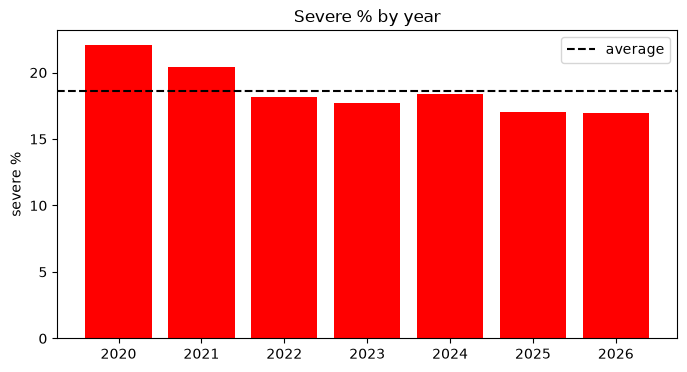

accident_year
2020    22.1
2021    20.4
2022    18.2
2023    17.7
2024    18.4
2025    17.0
2026    16.9
Name: severe, dtype: float64

In [35]:
# % รุนแรงแยกตามปี
plot_severe_percent(df_clean["accident_year"], "Severe % by year")

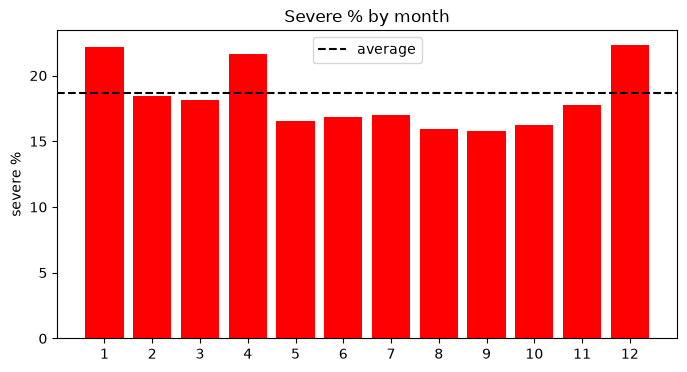

accident_date
1     22.1
2     18.4
3     18.2
4     21.7
5     16.6
6     16.9
7     17.0
8     15.9
9     15.8
10    16.2
11    17.8
12    22.3
Name: severe, dtype: float64

In [36]:
# % รุนแรงแยกตามเดือน (1-12)
month = df_clean["accident_date"].dt.month
plot_severe_percent(month, "Severe % by month")

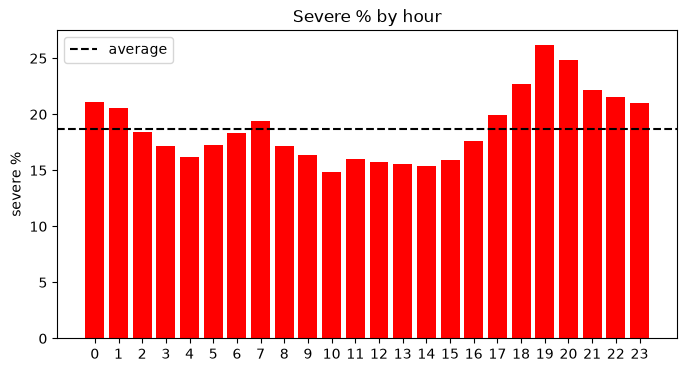

accident_time
0     21.1
1     20.6
2     18.4
3     17.2
4     16.2
5     17.2
6     18.4
7     19.4
8     17.2
9     16.4
10    14.8
11    16.0
12    15.7
13    15.6
14    15.4
15    15.9
16    17.6
17    19.9
18    22.7
19    26.2
20    24.8
21    22.2
22    21.6
23    21.0
Name: severe, dtype: float64

In [37]:
# % รุนแรงแยกตามชั่วโมงที่เกิดเหตุ (0-23) โดยตัด 2 ตัวแรกของเวลา "HH:MM"
hour = df_clean["accident_time"].str[:2].astype(int)
plot_severe_percent(hour, "Severe % by hour")

weather
clear          128819
rain            18223
unknown           878
fog/smoke         544
overcast          362
other              91
storm/flood        74
Name: count, dtype: int64


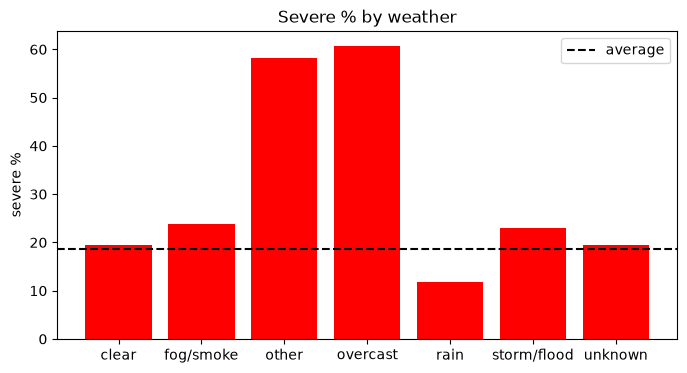

weather
clear          19.4
fog/smoke      23.9
other          58.2
overcast       60.8
rain           11.8
storm/flood    23.0
unknown        19.5
Name: severe, dtype: float64

In [38]:
# % รุนแรงแยกตามสภาพอากาศ (แปลงชื่อเป็นภาษาอังกฤษเพื่อแสดงบนกราฟ)
weather_english = {
    "แจ่มใส": "clear",
    "ฝนตก": "rain",
    "มีหมอก/ควัน/ฝุ่น": "fog/smoke",
    "มืดครึ้ม": "overcast",
    "ภัยธรรมชาติ เช่น พายุ น้ำท่วม": "storm/flood",
    "อื่นๆ": "other",
}
weather = df_clean["weather"].map(weather_english).fillna("unknown")

print(weather.value_counts())
plot_severe_percent(weather, "Severe % by weather")

agency
highway       140190
rural road      6836
expressway      1965
Name: count, dtype: int64


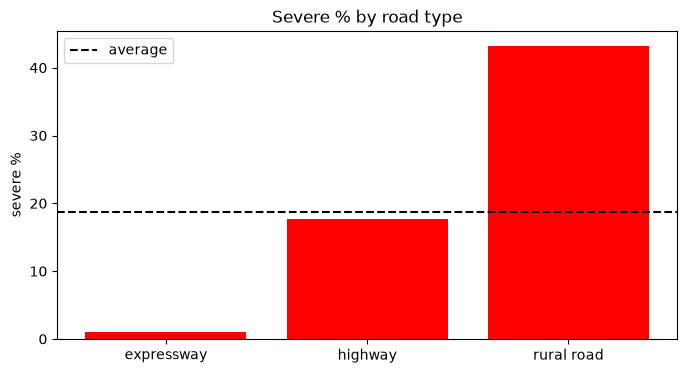

agency
expressway     1.0
highway       17.7
rural road    43.3
Name: severe, dtype: float64

In [39]:
# % รุนแรงแยกตามประเภทถนน (หน่วยงานที่ดูแล)
road_type_english = {
    "กรมทางหลวง": "highway",
    "กรมทางหลวงชนบท": "rural road",
    "การทางพิเศษแห่งประเทศไทย": "expressway",
}
road_type = df_clean["agency"].map(road_type_english)

print(road_type.value_counts())
plot_severe_percent(road_type, "Severe % by road type")

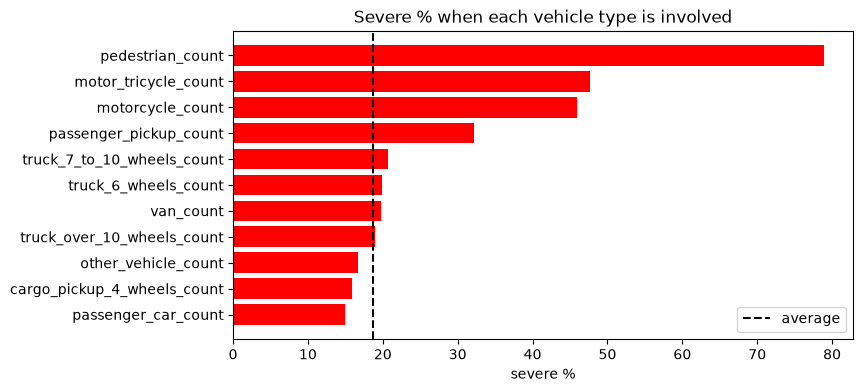

,involved,crashes,severe_percent
10,pedestrian_count,1537,78.9
1,motor_tricycle_count,1041,47.6
0,motorcycle_count,32103,45.9
4,passenger_pickup_count,843,32.1
7,truck_7_to_10_wheels_count,6516,20.7
6,truck_6_wheels_count,8600,19.9
3,van_count,3548,19.7
8,truck_over_10_wheels_count,16655,19.0
9,other_vehicle_count,9504,16.7
5,cargo_pickup_4_wheels_count,69352,15.9


In [40]:
# % รุนแรงเมื่อมีรถแต่ละประเภท (หรือคนเดินเท้า) เกี่ยวข้อง
vehicle_columns = [
    "motorcycle_count", "motor_tricycle_count", "passenger_car_count", "van_count",
    "passenger_pickup_count", "cargo_pickup_4_wheels_count", "truck_6_wheels_count",
    "truck_7_to_10_wheels_count", "truck_over_10_wheels_count", "other_vehicle_count",
]

rows = []
for column in vehicle_columns + ["pedestrian_count"]:
    involved = df_clean[df_clean[column] > 0]
    rows.append({
        "involved": column,
        "crashes": len(involved),
        "severe_percent": involved["severe"].mean() * 100,
    })

involved_table = pd.DataFrame(rows).sort_values("severe_percent")

plt.barh(involved_table["involved"], involved_table["severe_percent"], color="red")
plt.axvline(overall_percent, color="black", linestyle="--", label="average")
plt.title("Severe % when each vehicle type is involved")
plt.xlabel("severe %")
plt.legend()
plt.show()

involved_table.sort_values("severe_percent", ascending=False).round(1)

In [41]:
# % รุนแรงแยกตามลักษณะทาง (accident_location) ดู 10 แบบที่พบบ่อยที่สุด
location_table = df_clean.groupby("accident_location")["severe"].agg(["count", "mean"])
location_table.columns = ["crashes", "severe_rate"]
location_table["severe_percent"] = location_table["severe_rate"] * 100

print("จำนวนแบบของลักษณะทางทั้งหมด:", df_clean["accident_location"].nunique())
location_table.sort_values("crashes", ascending=False).head(10)[["crashes", "severe_percent"]].round(1)

จำนวนแบบของลักษณะทางทั้งหมด: 88


,crashes,severe_percent
accident_location,,
ทางตรง+ไม่มีความลาดชัน,89111,18.4
ทางตรง+ที่ราบ,14921,16.5
ทางโค้งกว้าง+ไม่มีความลาดชัน,13814,18.9
ทางโค้งกว้าง+ที่ลาดชัน,4757,14.1
ทางโค้งปกติ+ที่ราบ,2091,15.0
ทางตรง,1461,4.3
ทางเชื่อมเข้าพื้นที่สาธารณะ/เชิงพาณิชย์,1367,32.8
ทางตรง+ที่ลาดชัน,1177,21.0
ทางแยกรูปตัว T+ที่ราบ,1053,18.8


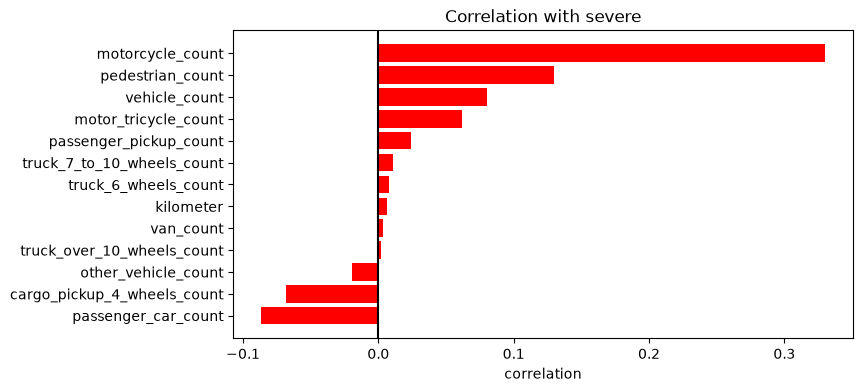

passenger_car_count           -0.087
cargo_pickup_4_wheels_count   -0.068
other_vehicle_count           -0.020
truck_over_10_wheels_count     0.002
van_count                      0.004
kilometer                      0.006
truck_6_wheels_count           0.008
truck_7_to_10_wheels_count     0.011
passenger_pickup_count         0.024
motor_tricycle_count           0.062
vehicle_count                  0.080
pedestrian_count               0.130
motorcycle_count               0.330
Name: severe, dtype: float64

In [42]:
# ค่า correlation ระหว่างคอลัมน์ตัวเลขกับ severe (ใกล้ 0 = แทบไม่สัมพันธ์, ใกล้ 1 หรือ -1 = สัมพันธ์มาก)
number_columns = vehicle_columns + ["pedestrian_count", "vehicle_count", "kilometer"]
correlation = df_clean[number_columns + ["severe"]].corr()["severe"]
correlation = correlation.drop("severe").sort_values()

plt.barh(correlation.index, correlation.values, color="red")
plt.axvline(0, color="black")
plt.title("Correlation with severe")
plt.xlabel("correlation")
plt.show()

correlation.round(3)

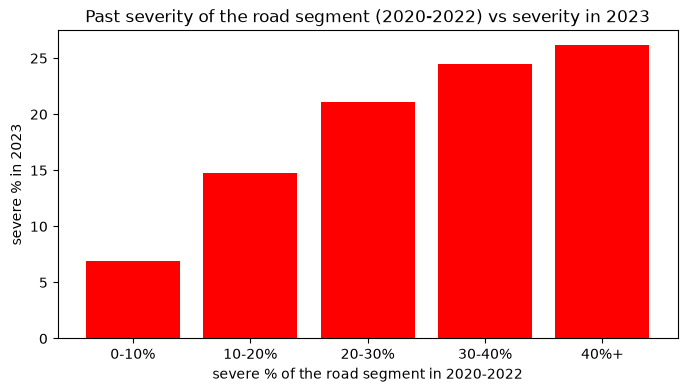

,crashes_in_2023,severe_rate_in_2023
past_band,,
0-10%,6577,0.069
10-20%,2979,0.148
20-30%,2206,0.211
30-40%,841,0.245
40%+,711,0.262


In [43]:
# ช่วงถนน 5 กม. ที่เคยรุนแรงในปี 2020-2022 ยังรุนแรงในปี 2023 ไหม
eda = df_clean.copy()
eda["road_block"] = eda["road_code"] + "_" + (eda["kilometer"] // 5 * 5).astype(int).astype(str)

# % รุนแรงในอดีตของแต่ละช่วงถนน (ใช้เฉพาะช่วงที่มีเหตุอย่างน้อย 10 ครั้ง)
past = eda[eda["accident_year"] <= 2022]
past_stats = past.groupby("road_block")["severe"].agg(["count", "mean"])
past_rate = past_stats[past_stats["count"] >= 10]["mean"]

def to_band(rate):
    if rate < 0.10:
        return "0-10%"
    if rate < 0.20:
        return "10-20%"
    if rate < 0.30:
        return "20-30%"
    if rate < 0.40:
        return "30-40%"
    return "40%+"

# เหตุปี 2023 บนช่วงถนนที่มีประวัติ แล้วจัดกลุ่มตามประวัติ
next_year = eda[eda["accident_year"] == 2023].copy()
next_year["past_rate"] = next_year["road_block"].map(past_rate)
next_year = next_year.dropna(subset=["past_rate"])
next_year["past_band"] = next_year["past_rate"].apply(to_band)

band_table = next_year.groupby("past_band")["severe"].agg(["count", "mean"])
band_table.columns = ["crashes_in_2023", "severe_rate_in_2023"]

plt.bar(band_table.index, band_table["severe_rate_in_2023"] * 100, color="red")
plt.title("Past severity of the road segment (2020-2022) vs severity in 2023")
plt.xlabel("severe % of the road segment in 2020-2022")
plt.ylabel("severe % in 2023")
plt.show()

band_table.round(3)

**สิ่งที่เห็นจากการสำรวจ**

- **สัดส่วนคำตอบ:** อุบัติเหตุรุนแรงคิดเป็น **18.6%** ของทั้งหมด ข้อมูลไม่สมดุล จึงต้องดู Precision และ Recall คู่กับ Accuracy
- **ผู้เกี่ยวข้องต่างกันมากที่สุด:** มีคนเดินเท้า **78.9%**, สามล้อเครื่อง **47.6%**, จักรยานยนต์ **45.9%** ส่วนรถยนต์นั่ง **14.9%** และ `corr()` สูงสุดคือ `motorcycle_count` (**0.33**)
- **เวลา:** ช่วง 18:00–20:59 สูงสุด (**22.7–26.2%**) ช่วง 10:00 ต่ำสุด (**14.8%**) ส่วนเดือน ธ.ค. ม.ค. เม.ย. อยู่ราว **22%** ขณะที่เดือนอื่นอยู่ที่ 16–18%
- **ประเภทถนน:** ทางหลวงชนบท **43.3%**, ทางหลวง **17.7%**, ทางพิเศษ **1.0%** (ส่วนหนึ่งอาจมาจากวิธีบันทึกของแต่ละหน่วยงานที่ต่างกัน)
- **อากาศ:** ฝนตก **11.8%** ต่ำกว่าอากาศแจ่มใส **19.4%**
- **ช่วงถนนเดิมรุนแรงซ้ำ:** ช่วงถนนที่เคยรุนแรง 40% ขึ้นไปในปี 2020–2022 พอถึงปี 2023 ยังรุนแรง **26.2%** ส่วนช่วงที่เคยต่ำกว่า 10% รุนแรงเพียง **6.9%** จึงนำประวัติช่วงถนนไปสร้างเป็นตัวแปร `road_history`

## 3. Model Planning
โมเดลแบบ classification: `X` = ถนน + สถานการณ์, `Y` = `severe` (1 หรือ 0)

### 3.1 Feature engineering
สร้างตัวแปรที่โมเดลใช้ จากคอลัมน์ที่ clean แล้ว

In [44]:
# คัดลอกข้อมูลที่ clean แล้ว มาเป็นตารางสำหรับโมเดล
model_data = df_clean.copy()
print(model_data.shape)

(148991, 40)


In [45]:
# ช่วงถนน 5 กม. (road_segment) เช่น ถนน 4225 กม. 6.6 อยู่ช่วง "4225_5"
km_block = (model_data["kilometer"] // 5 * 5).astype(int)
model_data["road_segment"] = model_data["road_code"] + "_" + km_block.astype(str)

model_data[["road_code", "kilometer", "road_segment"]].head()

,road_code,kilometer,road_segment
0,4225,6.600,4225_5
1,3473,37.000,3473_35
2,นภ.3038,7.275,นภ.3038_5
3,302,7.995,302_5
4,2196,29.300,2196_25


In [46]:
# ประวัติช่วงถนน (road_history): % รุนแรงของช่วงถนนนั้นในปี 2020-2022
# ใช้เฉพาะช่วงถนนที่มีเหตุอย่างน้อย 10 ครั้ง ช่วงอื่นใช้ค่าเฉลี่ยของทั้งประเทศแทน
history_years = model_data[model_data["accident_year"] <= 2022]
segment_stats = history_years.groupby("road_segment")["severe"].agg(["count", "mean"])
road_history_table = segment_stats[segment_stats["count"] >= 10]["mean"]
overall_history = history_years["severe"].mean()

model_data["road_history"] = model_data["road_segment"].map(road_history_table)
model_data["road_history"] = model_data["road_history"].fillna(overall_history)

print("จำนวนช่วงถนนที่มีประวัติ:", len(road_history_table))
print("ค่าเฉลี่ยทั้งประเทศ ปี 2020-2022:", round(overall_history, 3))
model_data[["road_segment", "road_history"]].head()

จำนวนช่วงถนนที่มีประวัติ: 1593
ค่าเฉลี่ยทั้งประเทศ ปี 2020-2022: 0.202


,road_segment,road_history
0,4225_5,0.202234
1,3473_35,0.202234
2,นภ.3038_5,0.202234
3,302_5,0.183673
4,2196_25,0.202234


In [47]:
# ประเภทถนน: ทางหลวงเป็นค่าตั้งต้น (rural_road = 0 และ expressway = 0)
model_data["rural_road"] = 0
model_data.loc[model_data["agency"] == "กรมทางหลวงชนบท", "rural_road"] = 1

model_data["expressway"] = 0
model_data.loc[model_data["agency"] == "การทางพิเศษแห่งประเทศไทย", "expressway"] = 1

print(model_data[["rural_road", "expressway"]].sum())

rural_road    6836
expressway    1965
dtype: int64


In [48]:
# ลักษณะทาง: จัดข้อความหลายสิบแบบให้เหลือไม่กี่กลุ่ม โดยดูคำสำคัญในข้อความ
def road_shape(text):
    if pd.isna(text):
        return "unknown"
    if "ทางโค้ง" in text:
        return "curve"
    if "แยก" in text:
        return "junction"
    if "ทางเชื่อม" in text or "เข้า" in text:
        return "access"
    if "ทางตรง" in text:
        return "straight"
    return "other"

model_data["road_shape"] = model_data["accident_location"].apply(road_shape)
model_data["road_shape"].value_counts()

road_shape
straight    107341
curve        22714
unknown      12572
junction      3435
access        2371
other          558
Name: count, dtype: int64[pyarrow]

In [49]:
# แปลงลักษณะทางเป็นคอลัมน์ 0/1 (ทางตรงและกลุ่มอื่นเป็นค่าตั้งต้น คือ 0 ทั้ง 3 คอลัมน์)
for shape in ["curve", "junction", "access"]:
    model_data[shape] = 0
    model_data.loc[model_data["road_shape"] == shape, shape] = 1

# ฝนตก (1) หรือไม่ตก (0) และชั่วโมงที่เกิดเหตุ (0-23)
model_data["rain"] = 0
model_data.loc[model_data["weather"] == "ฝนตก", "rain"] = 1

model_data["accident_hour"] = model_data["accident_time"].str[:2].astype(int)

model_data[["curve", "junction", "access", "rain", "accident_hour"]].head()

,curve,junction,access,rain,accident_hour
0,1,0,0,0,0
1,0,0,0,0,0
2,0,1,0,0,0
3,0,0,0,0,0
4,1,0,0,0,0


### 3.2 Feature selection
ใช้ `X` 20 คอลัมน์ เลือกเฉพาะสิ่งที่ผู้ใช้กรอกได้ก่อนเกิดเหตุ

| ตัดอะไร | เพราะอะไร |
|---|---|
| จำนวนผู้เสียชีวิตและผู้บาดเจ็บ | เป็นคำตอบเอง ถ้าใส่เท่ากับให้โมเดลดูเฉลย |
| สาเหตุ และลักษณะการชน | รู้ได้หลังเกิดเหตุแล้วเท่านั้น |
| รถคันแรก | ซ้ำกับจำนวนรถแต่ละประเภท |
| จังหวัด พิกัด รหัสถนน หลัก กม. | ใช้สร้าง `road_history` แล้ว |
| รถโดยสาร และรถอีแต๋น | เป็น 0 ทุกแถว (ดู cell ถัดไป) |
| เดือน | ลองเพิ่มแล้วคะแนนแทบไม่เปลี่ยน (ดู cell ตรวจท้ายข้อ 4.2) |

In [50]:
# รถโดยสารและรถอีแต๋นเป็น 0 ทุกแถว จึงไม่มีข้อมูลให้โมเดลเรียน
print(model_data[["bus_over_4_wheels_count", "farm_truck_count"]].sum())

bus_over_4_wheels_count    0
farm_truck_count           0
dtype: int64


In [51]:
# ตัวแปร X ทั้งหมด
feature_columns = (
    ["road_history", "rural_road", "expressway", "curve", "junction", "access"]
    + vehicle_columns
    + ["pedestrian_count", "vehicle_count", "accident_hour", "rain"]
)

print("จำนวนตัวแปร X:", len(feature_columns))
print(feature_columns)

จำนวนตัวแปร X: 20
['road_history', 'rural_road', 'expressway', 'curve', 'junction', 'access', 'motorcycle_count', 'motor_tricycle_count', 'passenger_car_count', 'van_count', 'passenger_pickup_count', 'cargo_pickup_4_wheels_count', 'truck_6_wheels_count', 'truck_7_to_10_wheels_count', 'truck_over_10_wheels_count', 'other_vehicle_count', 'pedestrian_count', 'vehicle_count', 'accident_hour', 'rain']


In [52]:
# ใช้เฉพาะเหตุปี 2023-2026 เพราะเหตุปี 2020-2022 ถูกใช้สร้าง road_history ไปแล้ว
# (ถ้าใช้ซ้ำ road_history ของเหตุนั้นจะมีคำตอบของตัวเองปนอยู่)
model_rows = model_data[model_data["accident_year"] >= 2023]

# เรียงตามวันและเวลาเกิดเหตุ เพื่อแบ่ง train/test ตามเวลา
model_rows = model_rows.sort_values(["accident_date", "accident_time"])

X = model_rows[feature_columns]
Y = model_rows["severe"]

print("X:", X.shape, "| Y:", Y.shape)
X.head()

X: (87483, 20) | Y: (87483,)


,road_history,rural_road,expressway,curve,junction,access,motorcycle_count,motor_tricycle_count,passenger_car_count,van_count,passenger_pickup_count,cargo_pickup_4_wheels_count,truck_6_wheels_count,truck_7_to_10_wheels_count,truck_over_10_wheels_count,other_vehicle_count,pedestrian_count,vehicle_count,accident_hour,rain
61508,0.202234,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0
61509,0.202234,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0
61510,0.202234,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0
61511,0.202234,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,2,0,0
61512,0.202234,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0


### 3.3 Train test split
แบ่งตามเวลา: 70% แรกเป็น `train` และ 30% หลังเป็น `test` เพราะเครื่องมือนี้ใช้ทายเหตุในอนาคต จึงต้องสอบด้วยช่วงเวลาที่มาทีหลัง

In [53]:
# shuffle=False คือไม่สับลำดับ จึงได้ 70% แรก (อดีต) เป็น train และ 30% หลัง (อนาคต) เป็น test
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, shuffle=False)

train_dates = model_rows.loc[X_train.index, "accident_date"]
test_dates = model_rows.loc[X_test.index, "accident_date"]

print("train:", X_train.shape, "|", train_dates.min().date(), "ถึง", train_dates.max().date(),
      "| severe %:", round(Y_train.mean() * 100, 1))
print("test :", X_test.shape, "|", test_dates.min().date(), "ถึง", test_dates.max().date(),
      "| severe %:", round(Y_test.mean() * 100, 1))

train: (61238, 20) | 2023-01-01 ถึง 2025-08-20 | severe %: 17.9
test : (26245, 20) | 2025-08-20 ถึง 2026-10-31 | severe %: 16.7


## 4. Build a model
ใช้ 3 โมเดล: Decision Tree, Random Forest, KNN

แต่ละโมเดลมีค่าที่ต้องตั้งเอง จึงลองหลายค่าแล้ววัดด้วย **5-fold cross-validation บนชุด `train`** และใช้ค่าที่ได้ accuracy สูงสุด (ไม่แตะชุด `test`)

In [54]:
# ฟังก์ชันวาดกราฟ accuracy ของ train เทียบกับ cross-validation
# ถ้าเส้น train ขึ้น แต่เส้น cross-validation ลง แปลว่าโมเดลเริ่มจำข้อมูล (overfitting)
def plot_trials(trials, setting_name, title):
    plt.plot(trials[setting_name], trials["train_accuracy"], marker="o", label="train")
    plt.plot(trials[setting_name], trials["cv_accuracy"], marker="o", label="cross-validation")
    plt.title(title)
    plt.xlabel(setting_name)
    plt.ylabel("accuracy")
    plt.legend()
    plt.show()

### 4.1 Decision Tree
ค่าที่ต้องตั้ง: `max_depth` คือจำนวนชั้นคำถามของต้นไม้

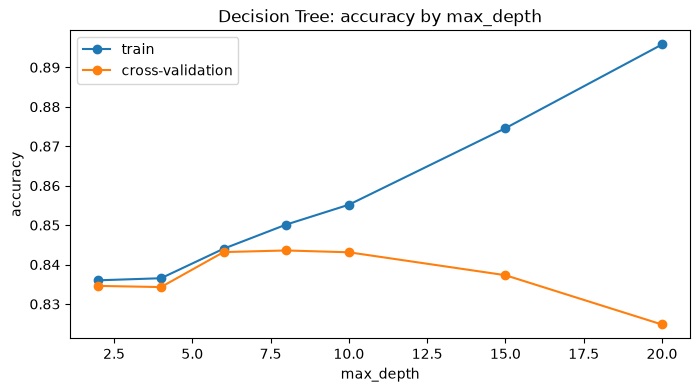

,max_depth,train_accuracy,cv_accuracy
0,2,0.8360,0.8346
1,4,0.8365,0.8343
2,6,0.8440,0.8432
3,8,0.8501,0.8436
4,10,0.8552,0.8431
5,15,0.8746,0.8373
6,20,0.8958,0.8248


In [55]:
# ลอง max_depth หลายค่า
rows = []
for depth in [2, 4, 6, 8, 10, 15, 20]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=1)
    cv_accuracy = cross_val_score(model, X_train, Y_train, cv=5).mean()

    model.fit(X_train, Y_train)
    train_accuracy = model.score(X_train, Y_train)

    rows.append({"max_depth": depth, "train_accuracy": train_accuracy, "cv_accuracy": cv_accuracy})

tree_trials = pd.DataFrame(rows)
plot_trials(tree_trials, "max_depth", "Decision Tree: accuracy by max_depth")
tree_trials.round(4)

In [56]:
# ใช้ค่าที่ cross-validation accuracy สูงสุด แล้วฝึกโมเดลด้วยชุด train
best_row = tree_trials.sort_values("cv_accuracy", ascending=False).iloc[0]
tree_depth = int(best_row["max_depth"])
print("max_depth ที่เลือก:", tree_depth)

tree_model = DecisionTreeClassifier(max_depth=tree_depth, random_state=1)
tree_model.fit(X_train, Y_train)

max_depth ที่เลือก: 8


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in 

### 4.2 Random Forest
ต้นไม้ 100 ต้นช่วยกันโหวต ค่าที่ต้องตั้ง: `max_depth` ของแต่ละต้น

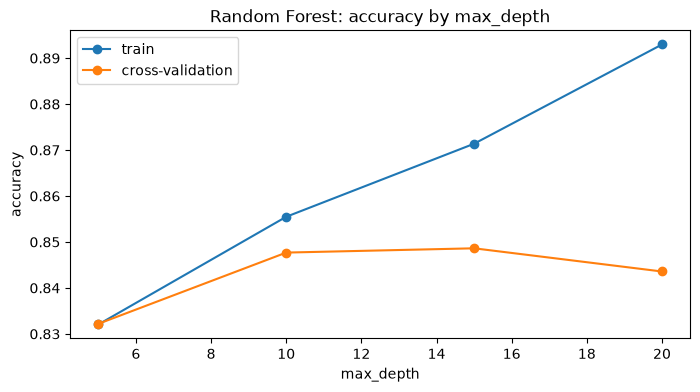

,max_depth,train_accuracy,cv_accuracy
0,5,0.8320,0.8322
1,10,0.8555,0.8477
2,15,0.8714,0.8486
3,20,0.8930,0.8436


In [57]:
# ลอง max_depth หลายค่า
rows = []
for depth in [5, 10, 15, 20]:
    model = RandomForestClassifier(max_depth=depth, random_state=1)
    cv_accuracy = cross_val_score(model, X_train, Y_train, cv=5).mean()

    model.fit(X_train, Y_train)
    train_accuracy = model.score(X_train, Y_train)

    rows.append({"max_depth": depth, "train_accuracy": train_accuracy, "cv_accuracy": cv_accuracy})

forest_trials = pd.DataFrame(rows)
plot_trials(forest_trials, "max_depth", "Random Forest: accuracy by max_depth")
forest_trials.round(4)

In [58]:
# ใช้ค่าที่ cross-validation accuracy สูงสุด แล้วฝึกโมเดลด้วยชุด train
best_row = forest_trials.sort_values("cv_accuracy", ascending=False).iloc[0]
forest_depth = int(best_row["max_depth"])
print("max_depth ที่เลือก:", forest_depth)

forest_model = RandomForestClassifier(max_depth=forest_depth, random_state=1)
forest_model.fit(X_train, Y_train)

max_depth ที่เลือก: 15


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [59]:
# ตรวจ: ถ้าเพิ่ม "เดือน" เป็นตัวแปรที่ 21 คะแนน cross-validation ดีขึ้นไหม
X_train_with_month = X_train.copy()
X_train_with_month["month"] = model_rows.loc[X_train.index, "accident_date"].dt.month

model = RandomForestClassifier(max_depth=forest_depth, random_state=1)
with_month = cross_val_score(model, X_train_with_month, Y_train, cv=5).mean()

print("ไม่มีเดือน (20 ตัวแปร):", round(forest_trials["cv_accuracy"].max(), 4))
print("มีเดือน   (21 ตัวแปร):", round(with_month, 4))

ไม่มีเดือน (20 ตัวแปร): 0.8486
มีเดือน   (21 ตัวแปร): 0.8497


### 4.3 KNN
ทายจากเหตุที่ "คล้ายที่สุด" k เหตุ ค่าที่ต้องตั้ง: `n_neighbors` (k) และต้องใช้ `StandardScaler` ปรับทุกคอลัมน์ให้มีขนาดใกล้กันก่อน เพราะ KNN วัดระยะห่าง

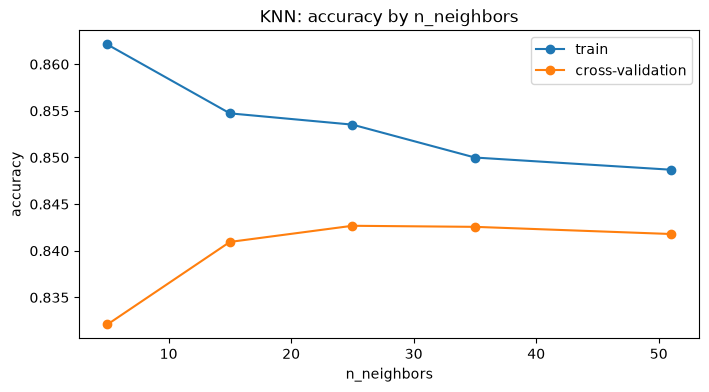

,n_neighbors,train_accuracy,cv_accuracy
0,5,0.8621,0.8321
1,15,0.8547,0.8409
2,25,0.8535,0.8427
3,35,0.8500,0.8426
4,51,0.8487,0.8418


In [60]:
# ลอง n_neighbors หลายค่า
rows = []
for k in [5, 15, 25, 35, 51]:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_accuracy = cross_val_score(model, X_train, Y_train, cv=5).mean()

    model.fit(X_train, Y_train)
    train_accuracy = model.score(X_train, Y_train)

    rows.append({"n_neighbors": k, "train_accuracy": train_accuracy, "cv_accuracy": cv_accuracy})

knn_trials = pd.DataFrame(rows)
plot_trials(knn_trials, "n_neighbors", "KNN: accuracy by n_neighbors")
knn_trials.round(4)

In [61]:
# ใช้ค่าที่ cross-validation accuracy สูงสุด แล้วฝึกโมเดลด้วยชุด train
best_row = knn_trials.sort_values("cv_accuracy", ascending=False).iloc[0]
knn_k = int(best_row["n_neighbors"])
print("n_neighbors ที่เลือก:", knn_k)

knn_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=knn_k))
knn_model.fit(X_train, Y_train)

n_neighbors ที่เลือก: 25


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['road_history','rural_road','expressway',...,'vehicle_count', 'accident_hour','rain']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 5. Evaluation metrics
ให้โมเดลทายชุด `test` ที่ไม่เคยเห็น แล้วเทียบกับคำตอบจริง

### 5.1 Confusion matrix
แถว = ความจริง, คอลัมน์ = ที่โมเดลทาย → ซ้ายบน `TN`, ขวาบน `FP`, ซ้ายล่าง `FN`, ขวาล่าง `TP`

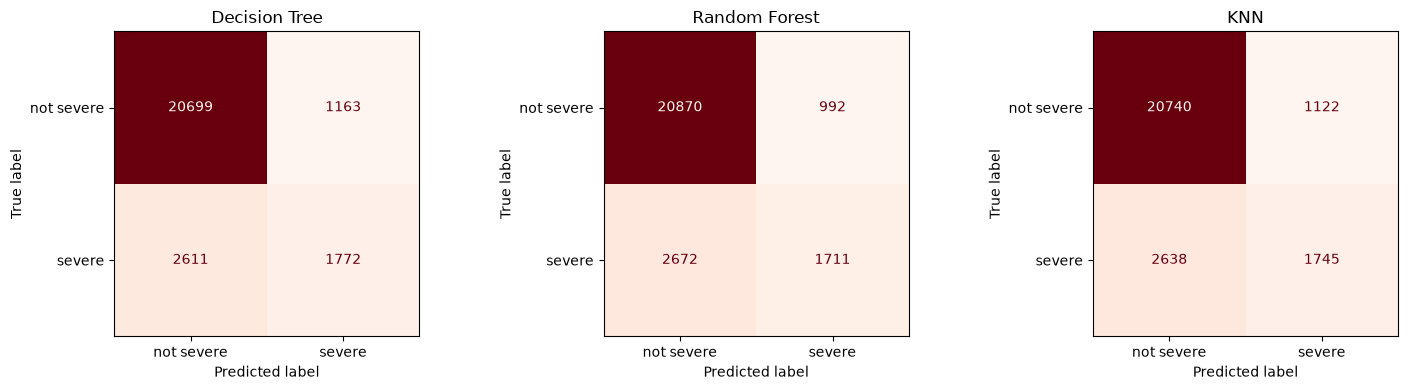

In [62]:
# ให้ทั้ง 3 โมเดลทายชุด test ด้วย predict()
models = {
    "Decision Tree": tree_model,
    "Random Forest": forest_model,
    "KNN": knn_model,
}

predictions = {}
for name in models:
    predictions[name] = models[name].predict(X_test)

# วาด confusion matrix ของแต่ละโมเดล
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
position = 0
for name in models:
    ConfusionMatrixDisplay.from_predictions(
        Y_test, predictions[name], display_labels=["not severe", "severe"],
        cmap="Reds", colorbar=False, ax=axes[position]
    )
    axes[position].set_title(name)
    position = position + 1

plt.tight_layout()
plt.show()

### 5.2 Accuracy, Precision, Recall, F1
- `Accuracy` = (TP + TN) / ทั้งหมด
- `Precision` = TP / (TP + FP) → ที่ทายว่ารุนแรง ถูกกี่ส่วน
- `Recall` = TP / (TP + FN) → เหตุรุนแรงจริง จับได้กี่ส่วน
- `F1` = 2 × Precision × Recall / (Precision + Recall) → รวม Precision กับ Recall เป็นเลขเดียว

In [63]:
# ฟังก์ชันคิดคะแนนจาก confusion matrix ด้วยสูตรข้างบน
def scores_from_predictions(name, y_true, y_pred):
    matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
    TN = matrix[0, 0]
    FP = matrix[0, 1]
    FN = matrix[1, 0]
    TP = matrix[1, 1]

    accuracy = (TP + TN) / (TP + TN + FP + FN)
    recall = TP / (TP + FN)

    precision = 0
    if TP + FP > 0:
        precision = TP / (TP + FP)

    f1 = 0
    if precision + recall > 0:
        f1 = 2 * precision * recall / (precision + recall)

    return {"model": name, "TN": TN, "FP": FP, "FN": FN, "TP": TP,
            "accuracy": accuracy, "precision": precision, "recall": recall, "F1": f1}

In [64]:
# เทียบ 3 โมเดล กับ baseline ที่ทายว่า "ไม่รุนแรง" ทุกครั้ง
always_not_severe = np.zeros(len(Y_test), dtype=int)

score_rows = []
score_rows.append(scores_from_predictions("baseline: always not severe", Y_test, always_not_severe))
for name in models:
    score_rows.append(scores_from_predictions(name, Y_test, predictions[name]))

score_table = pd.DataFrame(score_rows)
score_table.round(3)

,model,TN,FP,FN,TP,accuracy,precision,recall,F1
0,baseline: always not severe,21862,0,4383,0,0.833,0.000,0.000,0.000
1,Decision Tree,20699,1163,2611,1772,0.856,0.604,0.404,0.484
2,Random Forest,20870,992,2672,1711,0.860,0.633,0.390,0.483
3,KNN,20740,1122,2638,1745,0.857,0.609,0.398,0.481


### 5.3 Overfitting check
ถ้า accuracy บน `train` สูงกว่า `test` มาก แปลว่าโมเดลจำข้อมูล train

In [65]:
# accuracy บนชุด train เทียบกับชุด test
rows = []
for name in models:
    rows.append({
        "model": name,
        "train_accuracy": models[name].score(X_train, Y_train),
        "test_accuracy": models[name].score(X_test, Y_test),
    })

pd.DataFrame(rows).round(3)

,model,train_accuracy,test_accuracy
0,Decision Tree,0.850,0.856
1,Random Forest,0.871,0.860
2,KNN,0.854,0.857


### 5.4 เลือกเกณฑ์ตัดสินและโมเดลสุดท้าย
`predict()` ตัดสินว่า "รุนแรง" เมื่อโอกาสเกิน 50% แต่เหตุรุนแรงมีไม่ถึง 1 ใน 5 ของข้อมูล เกณฑ์ 50% จึงสูงเกินไปและจับเหตุรุนแรงได้น้อย

จึงลองเกณฑ์หลายค่า **บนชุด `train`** (ใช้ cross-validation เหมือนข้อ 4) แล้วเลือกโมเดลกับเกณฑ์ที่ `F1` สูงสุด

In [66]:
# ขอ % โอกาสรุนแรงของเหตุในชุด train แบบ cross-validation
# (แต่ละเหตุถูกทายโดยโมเดลที่ไม่ได้เรียนจากเหตุนั้น)
train_chance = {}
for name in models:
    chance = cross_val_predict(models[name], X_train, Y_train, cv=5, method="predict_proba")
    train_chance[name] = chance[:, 1]

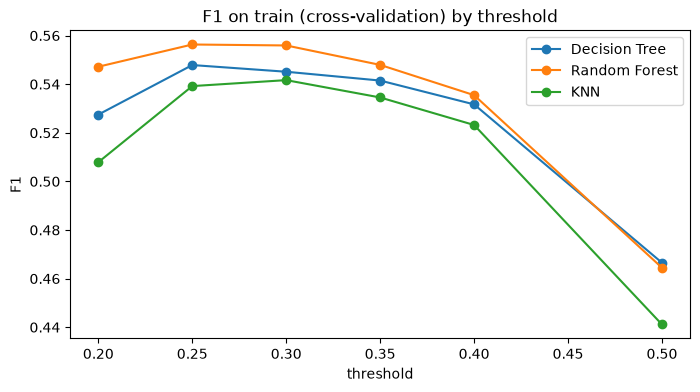

model,Decision Tree,KNN,Random Forest
threshold,,,
0.20,0.527,0.508,0.547
0.25,0.548,0.539,0.556
0.30,0.545,0.542,0.556
0.35,0.541,0.535,0.548
0.40,0.532,0.523,0.535
0.50,0.467,0.441,0.464


In [67]:
# ลองเกณฑ์ตัดสินหลายค่า แล้วเก็บ F1 บนชุด train
threshold_rows = []
for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.50]:
    for name in models:
        predicted = (train_chance[name] >= threshold).astype(int)
        scores = scores_from_predictions(name, Y_train, predicted)
        threshold_rows.append({"model": name, "threshold": threshold, "F1": scores["F1"]})

threshold_trials = pd.DataFrame(threshold_rows)

for name in models:
    one_model = threshold_trials[threshold_trials["model"] == name]
    plt.plot(one_model["threshold"], one_model["F1"], marker="o", label=name)
plt.title("F1 on train (cross-validation) by threshold")
plt.xlabel("threshold")
plt.ylabel("F1")
plt.legend()
plt.show()

pd.crosstab(threshold_trials["threshold"], threshold_trials["model"],
            values=threshold_trials["F1"], aggfunc="mean").round(3)

In [68]:
# เลือกโมเดลและเกณฑ์ที่ F1 บนชุด train สูงสุด
best_row = threshold_trials.sort_values("F1", ascending=False).iloc[0]
final_name = best_row["model"]
final_threshold = best_row["threshold"]
final_model = models[final_name]

print("โมเดลสุดท้าย:", final_name, "| เกณฑ์ตัดสิน:", final_threshold)

โมเดลสุดท้าย: Random Forest | เกณฑ์ตัดสิน: 0.25


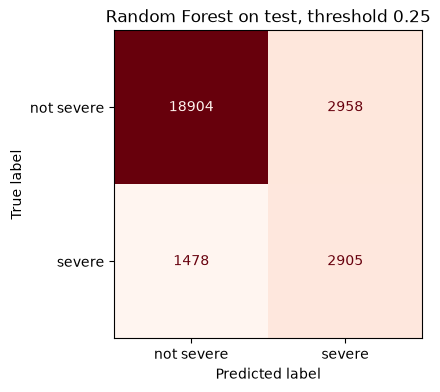

,model,TN,FP,FN,TP,accuracy,precision,recall,F1
0,baseline: always not severe,21862,0,4383,0,0.833,0.000,0.000,0.000
1,Random Forest (threshold 0.5),20870,992,2672,1711,0.860,0.633,0.390,0.483
2,Random Forest (threshold 0.25),18904,2958,1478,2905,0.831,0.495,0.663,0.567


In [69]:
# วัดผลครั้งสุดท้ายบนชุด test ด้วยโมเดลและเกณฑ์ที่เลือก
final_chance = final_model.predict_proba(X_test)[:, 1]
final_prediction = (final_chance >= final_threshold).astype(int)

ConfusionMatrixDisplay.from_predictions(
    Y_test, final_prediction, display_labels=["not severe", "severe"], cmap="Reds", colorbar=False
)
plt.title(final_name + " on test, threshold " + str(final_threshold))
plt.show()

final_rows = []
final_rows.append(scores_from_predictions("baseline: always not severe", Y_test, always_not_severe))
final_rows.append(scores_from_predictions(final_name + " (threshold 0.5)", Y_test, predictions[final_name]))
final_rows.append(scores_from_predictions(final_name + " (threshold " + str(final_threshold) + ")", Y_test, final_prediction))
final_table = pd.DataFrame(final_rows)
final_table.round(3)

In [70]:
# ตรวจว่าคิดคะแนนเองถูก ด้วย classification_report ของ sklearn
print(classification_report(Y_test, final_prediction, target_names=["not severe", "severe"]))

              precision    recall  f1-score   support

  not severe       0.93      0.86      0.89     21862
      severe       0.50      0.66      0.57      4383

    accuracy                           0.83     26245
   macro avg       0.71      0.76      0.73     26245
weighted avg       0.86      0.83      0.84     26245



## 6. Comparing factors using the model
วิธี: นำเหตุจริงในชุด `test` มา แล้วสมมติให้ทุกเหตุมีค่าปัจจัยหนึ่งเหมือนกัน เช่น ให้ทุกเหตุ "มีจักรยานยนต์" เทียบกับ "ไม่มี" แล้วดูว่า % รุนแรงเฉลี่ยที่โมเดลทายต่างกันกี่จุด

In [71]:
# % โอกาสรุนแรงมาจากไหน: predict_proba คืนโอกาสของ [ไม่รุนแรง, รุนแรง] ของแต่ละเหตุ
example = X_test.head(5).copy()
example["severe_percent"] = final_model.predict_proba(X_test.head(5))[:, 1] * 100
example["actual_severe"] = Y_test.head(5)
example[["road_history", "motorcycle_count", "pedestrian_count", "accident_hour", "severe_percent", "actual_severe"]].round(2)

,road_history,motorcycle_count,pedestrian_count,accident_hour,severe_percent,actual_severe
122746,0.03,1,0,20,14.87,1
122747,0.24,0,0,21,9.73,0
122748,0.2,1,0,21,53.05,1
122749,0.2,1,0,22,81.74,1
122750,0.01,0,0,23,2.94,0


In [72]:
# ใช้เหตุ 5,000 ครั้งจากชุด test เป็นตัวแทน เพื่อให้รันเร็ว
what_if_data = X_test.sample(5000, random_state=1)

# ฟังก์ชัน: เปลี่ยนค่าบางคอลัมน์ให้ทุกเหตุ แล้วคืน % รุนแรงเฉลี่ยที่โมเดลทาย
def average_percent(changes):
    changed = what_if_data.copy()
    for column in changes:
        changed[column] = changes[column]
    return final_model.predict_proba(changed)[:, 1].mean() * 100

print("% รุนแรงเฉลี่ยที่โมเดลทาย เมื่อยังไม่เปลี่ยนอะไร:", round(average_percent({}), 1))

% รุนแรงเฉลี่ยที่โมเดลทาย เมื่อยังไม่เปลี่ยนอะไร: 17.7


### 6.1 เปลี่ยนทีละปัจจัย (มี / ไม่มี)

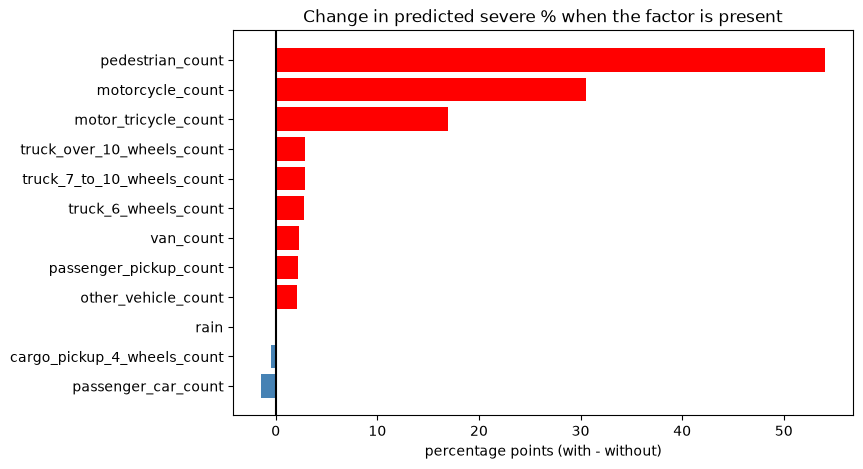

,factor,percent_without,percent_with,change
10,pedestrian_count,17.2,71.2,54.0
0,motorcycle_count,12.8,43.4,30.5
1,motor_tricycle_count,17.6,34.5,16.9
8,truck_over_10_wheels_count,17.5,20.4,2.9
7,truck_7_to_10_wheels_count,17.6,20.4,2.8
6,truck_6_wheels_count,17.6,20.3,2.7
3,van_count,17.6,19.9,2.3
4,passenger_pickup_count,17.6,19.8,2.2
9,other_vehicle_count,17.7,19.7,2.0
11,rain,17.7,17.6,-0.1


In [73]:
# ให้ทุกเหตุ "ไม่มี" ปัจจัยนี้ (0) เทียบกับ "มี" ปัจจัยนี้ (1)
effect_rows = []
for factor in vehicle_columns + ["pedestrian_count", "rain"]:
    percent_without = average_percent({factor: 0})
    percent_with = average_percent({factor: 1})
    effect_rows.append({
        "factor": factor,
        "percent_without": percent_without,
        "percent_with": percent_with,
        "change": percent_with - percent_without,
    })

effect_table = pd.DataFrame(effect_rows).sort_values("change")

# สีแดง = ทำให้ % รุนแรงเพิ่ม, สีฟ้า = ทำให้ลด
colors = []
for change in effect_table["change"]:
    if change > 0:
        colors.append("red")
    else:
        colors.append("steelblue")

plt.figure(figsize=(8, 5))
plt.barh(effect_table["factor"], effect_table["change"], color=colors)
plt.axvline(0, color="black")
plt.title("Change in predicted severe % when the factor is present")
plt.xlabel("percentage points (with - without)")
plt.show()

effect_table.sort_values("change", ascending=False).round(1)

### 6.2 ปัจจัยที่มีหลายค่า

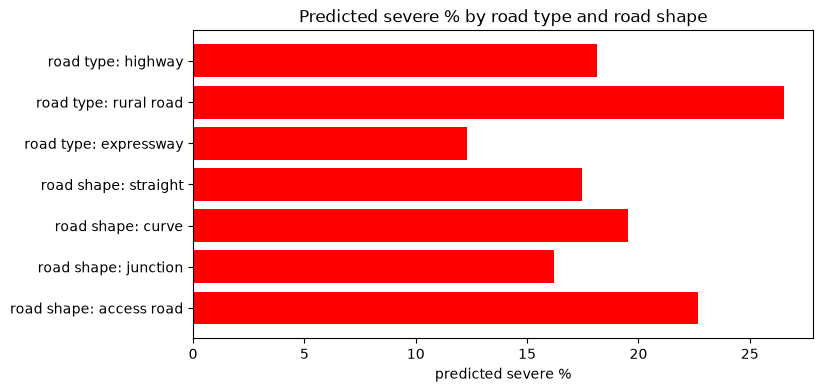

,scenario,predicted_percent
0,road type: highway,18.1
1,road type: rural road,26.5
2,road type: expressway,12.3
3,road shape: straight,17.5
4,road shape: curve,19.5
5,road shape: junction,16.2
6,road shape: access road,22.7


In [74]:
# ประเภทถนน และลักษณะทาง: ลองทีละแบบ
scenarios = {
    "road type: highway": {"rural_road": 0, "expressway": 0},
    "road type: rural road": {"rural_road": 1, "expressway": 0},
    "road type: expressway": {"rural_road": 0, "expressway": 1},
    "road shape: straight": {"curve": 0, "junction": 0, "access": 0},
    "road shape: curve": {"curve": 1, "junction": 0, "access": 0},
    "road shape: junction": {"curve": 0, "junction": 1, "access": 0},
    "road shape: access road": {"curve": 0, "junction": 0, "access": 1},
}

scenario_rows = []
for name in scenarios:
    scenario_rows.append({"scenario": name, "predicted_percent": average_percent(scenarios[name])})

scenario_table = pd.DataFrame(scenario_rows)

plt.barh(scenario_table["scenario"], scenario_table["predicted_percent"], color="red")
plt.gca().invert_yaxis()
plt.title("Predicted severe % by road type and road shape")
plt.xlabel("predicted severe %")
plt.show()

scenario_table.round(1)

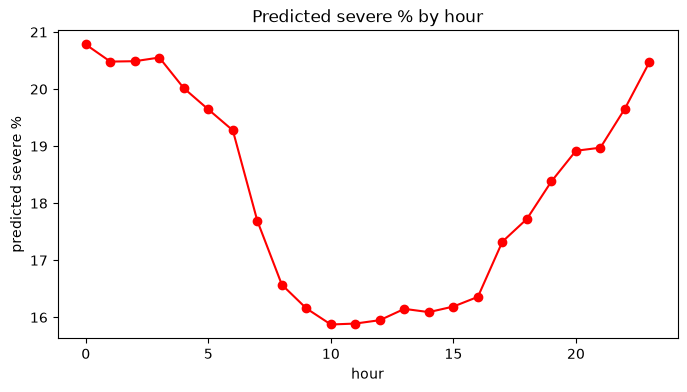

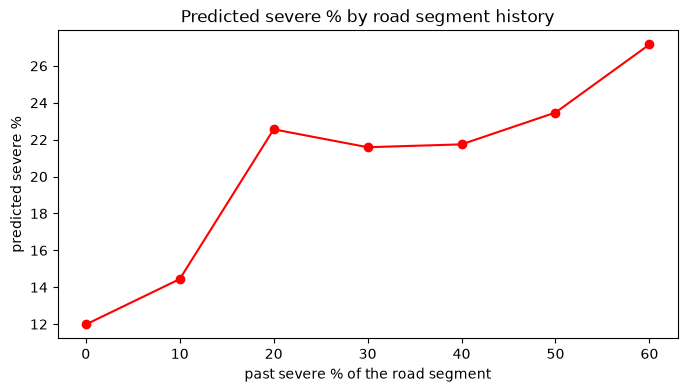

,road_history_percent,predicted_percent
0,0.0,12.0
1,10.0,14.4
2,20.0,22.6
3,30.0,21.6
4,40.0,21.7
5,50.0,23.5
6,60.0,27.2


In [75]:
# ชั่วโมงที่เกิดเหตุ: ลองให้ทุกเหตุเกิดตอน 0, 1, ..., 23 นาฬิกา
hour_percent = []
for hour in range(24):
    hour_percent.append(average_percent({"accident_hour": hour}))

plt.plot(range(24), hour_percent, marker="o", color="red")
plt.title("Predicted severe % by hour")
plt.xlabel("hour")
plt.ylabel("predicted severe %")
plt.show()

# ประวัติช่วงถนน: ลองให้ทุกเหตุอยู่บนถนนที่เคยรุนแรง 0%, 10%, ..., 60%
history_values = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
history_percent = []
for value in history_values:
    history_percent.append(average_percent({"road_history": value}))

plt.plot(np.array(history_values) * 100, history_percent, marker="o", color="red")
plt.title("Predicted severe % by road segment history")
plt.xlabel("past severe % of the road segment")
plt.ylabel("predicted severe %")
plt.show()

pd.DataFrame({"road_history_percent": np.array(history_values) * 100, "predicted_percent": history_percent}).round(1)

### 6.3 Heatmap 2 ปัจจัย (brute force)
ลองทุกคู่ของ "ใครเกี่ยวข้อง" × "ชั่วโมง" (11 × 24 = 264 แบบ) แล้วระบายสีตาม % ที่โมเดลทาย

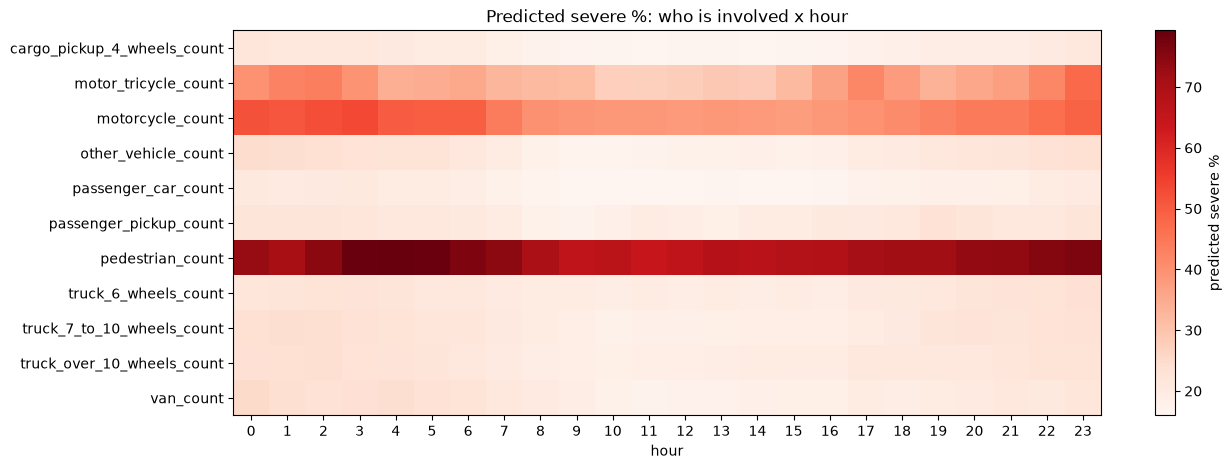

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
involved,,,,,,,,,,,,,,,,,,,,,
cargo_pickup_4_wheels_count,21.0,21.0,21.0,21.0,20.0,20.0,20.0,18.0,17.0,17.0,...,16.0,16.0,17.0,17.0,18.0,19.0,19.0,19.0,20.0,21.0
motor_tricycle_count,40.0,43.0,43.0,39.0,34.0,35.0,35.0,33.0,32.0,31.0,...,28.0,32.0,37.0,42.0,38.0,33.0,36.0,37.0,42.0,48.0
motorcycle_count,52.0,51.0,52.0,53.0,50.0,49.0,50.0,44.0,40.0,39.0,...,38.0,38.0,39.0,40.0,41.0,43.0,44.0,44.0,47.0,49.0
other_vehicle_count,24.0,24.0,23.0,23.0,23.0,22.0,21.0,20.0,18.0,17.0,...,18.0,18.0,18.0,20.0,20.0,21.0,22.0,22.0,23.0,23.0
passenger_car_count,21.0,20.0,20.0,20.0,20.0,20.0,19.0,18.0,17.0,16.0,...,16.0,16.0,16.0,17.0,17.0,18.0,18.0,18.0,19.0,20.0
passenger_pickup_count,22.0,22.0,22.0,22.0,21.0,21.0,20.0,19.0,18.0,17.0,...,19.0,19.0,21.0,20.0,21.0,23.0,22.0,21.0,21.0,22.0
pedestrian_count,73.0,71.0,74.0,79.0,79.0,79.0,76.0,74.0,70.0,66.0,...,67.0,68.0,69.0,71.0,72.0,72.0,74.0,74.0,76.0,77.0
truck_6_wheels_count,22.0,22.0,23.0,22.0,22.0,21.0,21.0,20.0,19.0,19.0,...,19.0,19.0,19.0,20.0,20.0,21.0,22.0,22.0,23.0,23.0
truck_7_to_10_wheels_count,24.0,24.0,24.0,23.0,22.0,22.0,22.0,20.0,19.0,18.0,...,19.0,19.0,19.0,20.0,20.0,22.0,22.0,22.0,23.0,23.0


In [76]:
# วนทุกคู่ แล้วเก็บ % รุนแรงที่โมเดลทาย
heat_rows = []
for factor in vehicle_columns + ["pedestrian_count"]:
    for hour in range(24):
        percent = average_percent({factor: 1, "accident_hour": hour})
        heat_rows.append({"involved": factor, "hour": hour, "percent": percent})

heat_table = pd.DataFrame(heat_rows)

# จัดเป็นตาราง: แถว = ใครเกี่ยวข้อง, คอลัมน์ = ชั่วโมง
heat_grid = pd.crosstab(heat_table["involved"], heat_table["hour"],
                        values=heat_table["percent"], aggfunc="mean")

plt.figure(figsize=(14, 5))
plt.imshow(heat_grid, cmap="Reds", aspect="auto")
plt.colorbar(label="predicted severe %")
plt.xticks(range(24), heat_grid.columns)
plt.yticks(range(len(heat_grid)), heat_grid.index)
plt.title("Predicted severe %: who is involved x hour")
plt.xlabel("hour")
plt.show()

heat_grid.round(0)

### 6.4 ลองใช้
ใส่ถนน + หลัก กม. + สถานการณ์ → ได้ % โอกาสรุนแรง

In [77]:
# ฟังก์ชันทาย % รุนแรงของสถานการณ์ที่กำหนด
def predict_severity(road_code, kilometer, involved, hour, rain, shape):
    road_rows = model_data[model_data["road_code"] == road_code]
    if len(road_rows) == 0:
        return "ไม่พบรหัสถนนนี้ในข้อมูล"

    # เริ่มจากแถวที่ทุกคอลัมน์เป็น 0
    row = pd.DataFrame(0.0, index=[0], columns=feature_columns)

    # 1) ถนน: หาประวัติของช่วงถนน 5 กม. (ถ้าไม่มีประวัติ ใช้ค่าเฉลี่ยทั้งประเทศ)
    segment = road_code + "_" + str(int(kilometer // 5 * 5))
    row["road_history"] = overall_history
    if segment in road_history_table.index:
        row["road_history"] = road_history_table[segment]

    agency = road_rows["agency"].iloc[0]
    if agency == "กรมทางหลวงชนบท":
        row["rural_road"] = 1
    if agency == "การทางพิเศษแห่งประเทศไทย":
        row["expressway"] = 1

    # 2) ลักษณะทาง: "straight", "curve", "junction" หรือ "access"
    if shape in ["curve", "junction", "access"]:
        row[shape] = 1

    # 3) รถและคนที่เกี่ยวข้อง (คนเดินเท้าไม่นับเป็นจำนวนรถ)
    for column in involved:
        row[column] = row[column] + 1
        if column != "pedestrian_count":
            row["vehicle_count"] = row["vehicle_count"] + 1

    # 4) เวลาและอากาศ
    row["accident_hour"] = hour
    row["rain"] = rain

    return round(final_model.predict_proba(row)[0, 1] * 100, 1)

In [78]:
# ตัวอย่าง: ถนนหมายเลข 3 กม. 332 เทียบ 3 สถานการณ์
examples = [
    {"scenario": "motorcycle, 22:00, curve", "involved": ["motorcycle_count"], "hour": 22, "rain": 0, "shape": "curve"},
    {"scenario": "car + pickup, 10:00, straight", "involved": ["passenger_car_count", "cargo_pickup_4_wheels_count"], "hour": 10, "rain": 0, "shape": "straight"},
    {"scenario": "car + pedestrian, 20:00, straight", "involved": ["passenger_car_count", "pedestrian_count"], "hour": 20, "rain": 0, "shape": "straight"},
]

example_rows = []
for ex in examples:
    percent = predict_severity("3", 332, ex["involved"], ex["hour"], ex["rain"], ex["shape"])
    example_rows.append({"road": "3", "kilometer": 332, "scenario": ex["scenario"], "severe_percent": percent})

pd.DataFrame(example_rows)

,road,kilometer,scenario,severe_percent
0,3,332,"motorcycle, 22:00, curve",70.1
1,3,332,"car + pickup, 10:00, straight",20.7
2,3,332,"car + pedestrian, 20:00, straight",90.1


## 7. Save model to file
บันทึกโมเดลสุดท้ายและตารางประวัติช่วงถนน เพื่อนำไปใช้ต่อโดยไม่ต้องฝึกใหม่

In [79]:
# บันทึกลงโฟลเดอร์ model/
os.makedirs("model", exist_ok=True)

joblib.dump(final_model, "model/road_severity_model.joblib")
road_history_table.to_csv("model/road_history.csv")
pd.Series(feature_columns).to_csv("model/feature_columns.csv", index=False, header=["feature"])

size_mb = os.path.getsize("model/road_severity_model.joblib") / 1000000
print("บันทึกแล้ว | ขนาดไฟล์โมเดล:", round(size_mb, 1), "MB")

บันทึกแล้ว | ขนาดไฟล์โมเดล: 25.2 MB


In [80]:
# โหลดโมเดลกลับมาแล้วทายชุด test ซ้ำ เพื่อยืนยันว่าไฟล์ใช้ได้จริง
loaded_model = joblib.load("model/road_severity_model.joblib")
loaded_chance = loaded_model.predict_proba(X_test)[:, 1]

print("ทายได้ค่าเดียวกับก่อนบันทึก:", (loaded_chance == final_chance).all())

ทายได้ค่าเดียวกับก่อนบันทึก: True


## 8. Conclusion

| หัวข้อ | ผล |
|---|---|
| ข้อมูล | 151,823 แถว เหลือ **148,991** แถวหลัง clean ใช้ปี 2020–2022 สร้างประวัติช่วงถนน และปี 2023–2026 (**87,483** เหตุ) สร้างโมเดล |
| `X` และ `Y` | `X` 20 คอลัมน์ (ถนน ลักษณะทาง รถและคน ชั่วโมง ฝน) และ `Y` = `severe` |
| การแบ่งข้อมูล | ตามเวลา: `train` 61,238 เหตุ (1 ม.ค. 2023 – 20 ส.ค. 2025) และ `test` 26,245 เหตุ (20 ส.ค. 2025 – 31 ต.ค. 2026) |
| ค่าตั้งจาก cross-validation | Decision Tree `max_depth=8`, Random Forest `max_depth=15`, KNN `n_neighbors=25` |
| Accuracy บน `test` (เกณฑ์ 50%) | Decision Tree **0.856**, Random Forest **0.860**, KNN **0.857** เทียบกับทายว่าไม่รุนแรงทุกครั้ง **0.833** |
| โมเดลสุดท้าย | **Random Forest** เกณฑ์ตัดสิน **0.25**: Precision **0.495**, Recall **0.663**, F1 **0.567**, Accuracy **0.831** |

- **ปัจจัยที่ทำให้ % รุนแรงเพิ่มมากที่สุด:** มีคนเดินเท้า **+54.0** จุด, มีจักรยานยนต์ **+30.5** จุด, มีสามล้อเครื่อง **+16.9** จุด ส่วนฝนแทบไม่มีผล (**−0.1** จุด)
- **ถนน:** ทางหลวงชนบท **26.5%** เทียบกับทางหลวง **18.1%** และทางพิเศษ **12.3%** ช่วงถนนที่เคยรุนแรง 60% ถูกทายที่ **27.2%** เทียบกับ **12.0%** ของช่วงที่ไม่เคยรุนแรงเลย
- **ลักษณะทาง:** ทางเชื่อมเข้าพื้นที่ **22.7%**, ทางโค้ง **19.5%**, ทางตรง **17.5%**, ทางแยก **16.2%**
- **วิธีอ่านผลโมเดลสุดท้าย:** จับเหตุรุนแรงได้ 66% (2,905 จาก 4,383 เหตุ) แต่เมื่อทายว่ารุนแรงจะถูกราวครึ่งหนึ่ง Accuracy จึงต่ำกว่าการทายว่าไม่รุนแรงทุกครั้งเล็กน้อย (0.831 กับ 0.833) เพราะเลือกจับเหตุรุนแรงให้ได้มากขึ้น แลกกับการเตือนผิดที่มากขึ้น
- **ข้อจำกัด:** ผลเป็นความสัมพันธ์ ไม่ใช่การพิสูจน์สาเหตุ / ข้อมูลไม่มีความเร็ว หมวกนิรภัย หรือเข็มขัดนิรภัย / มีประวัติเพียง 1,593 ช่วงถนน ช่วงอื่นใช้ค่าเฉลี่ยทั้งประเทศ / ปี 2023 บันทึกลักษณะทางด้วยชุดคำที่ต่างจากปีอื่น / แต่ละหน่วยงานบันทึกเหตุเล็กน้อยไม่เท่ากัน